# 5 · EDA — Exploratory Data Analysis

**Bài toán:** Dự đoán phí vận chuyển `freight_value` (BRL/item) từ **108.937 item, 10 cột**

## 0. Chuẩn bị dữ liệu

Đọc **CSV clean chính thức**, một dòng = một item trong đơn hàng (`order_id`, `order_item_id`). EDA không sửa dữ liệu gốc.

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/cleaned/olist_clean.csv")

print("Shape cleaned:", df.shape)


Shape cleaned: (108937, 10)


**Kiểm tra:** File có 108.937 dòng × 10 cột; các phép kiểm chất lượng ở mục 1 được thực hiện riêng.

## 1. Kiểm tra dữ liệu sau Cleaning

### 1.1. Cấu trúc dữ liệu

**Mục đích:** Xác nhận các cột và kiểu dữ liệu thực sự có trong CSV.

In [28]:
print(df.dtypes)


order_id                     object
order_item_id                 int64
seller_id                    object
order_purchase_timestamp     object
price                       float64
weight_g                    float64
volume_cm3                  float64
distance_km                 float64
category                     object
freight_value               float64
dtype: object


**Kết quả:** 108.937 item, 10 cột; `freight_value` là target. Chỉ phân tích những biến có trong CSV, không sử dụng ngầm các cột của SQL bản cũ.

### 1.2. Giá trị thiếu và trùng khóa

**Kiểm tra:** Thiếu dữ liệu, khóa trùng `(order_id, order_item_id)` và khóa bị thiếu.

In [29]:

print("Giá trị thiếu:",df.isnull().sum().sum(), 
      "\nTrùng khóa:",df[["order_id","order_item_id"]].duplicated().sum())

Giá trị thiếu: 0 
Trùng khóa: 0


**Kết quả:** 0 ô thiếu, 0 khóa trùng, 0 khóa thiếu. 
**Quyết định:** Tiếp tục EDA; điều này chưa khẳng định mọi giá trị đều chính xác.

### 1.3. Miền giá trị cơ bản

**Kiểm tra:** `freight_value`, `distance_km` không âm; `price`, `weight_g`, `volume_cm3` > 0.

In [30]:
freight_value_check = (df["freight_value"] < 0).sum()
price_check = (df["price"] <= 0).sum()
weight_g_check = (df["weight_g"] <= 0).sum()
distance_km_check = (df["distance_km"] < 0).sum()
volume_cm3_check = (df["volume_cm3"] <= 0).sum()

df1_3 = pd.DataFrame({
    "Check" : ["freight_value_check","price_check","weight_g_check","distance_km_check","volume_cm3_check"],
    "Value" : [freight_value_check,price_check,weight_g_check,distance_km_check,volume_cm3_check]
})
display(df1_3)

,Check,Value
0,freight_value_check,0
1,price_check,0
2,weight_g_check,0
3,distance_km_check,0
4,volume_cm3_check,0


### 1.4. Kiểu thời gian

Chuyển `order_purchase_timestamp` sang `datetime` để phân tích theo tháng.

In [31]:
df["order_purchase_timestamp"] = pd.to_datetime(df["order_purchase_timestamp"])
print("Dtypes column:",df["order_purchase_timestamp"].dtypes)

Dtypes column: datetime64[ns]


**Kết quả:** Chuyển thành công, không có `NaT`. Sử dụng `YYYY-MM` để không gộp nhầm hai năm.

## 2. Phân tích biến mục tiêu `freight_value`

**Mục đích:** Biết mức phí điển hình, đuôi phân phối và biến động theo tháng để quyết định cách đánh giá mô hình.

### 2.1. Phân phối và outlier

**Phương pháp:** `describe()`, histogram, IQR và boxplot. `showfliers=False` chỉ ẩn điểm cực đoan trên hình, **không xóa dữ liệu**.

In [32]:
freight_value_2_1 = df["freight_value"].describe().round(3).reset_index()
display(freight_value_2_1)

,index,freight_value
0,count,108937.000
1,mean,20.012
2,std,15.701
3,min,0.010
4,25%,13.080
5,50%,16.280
6,75%,21.150
7,max,409.680


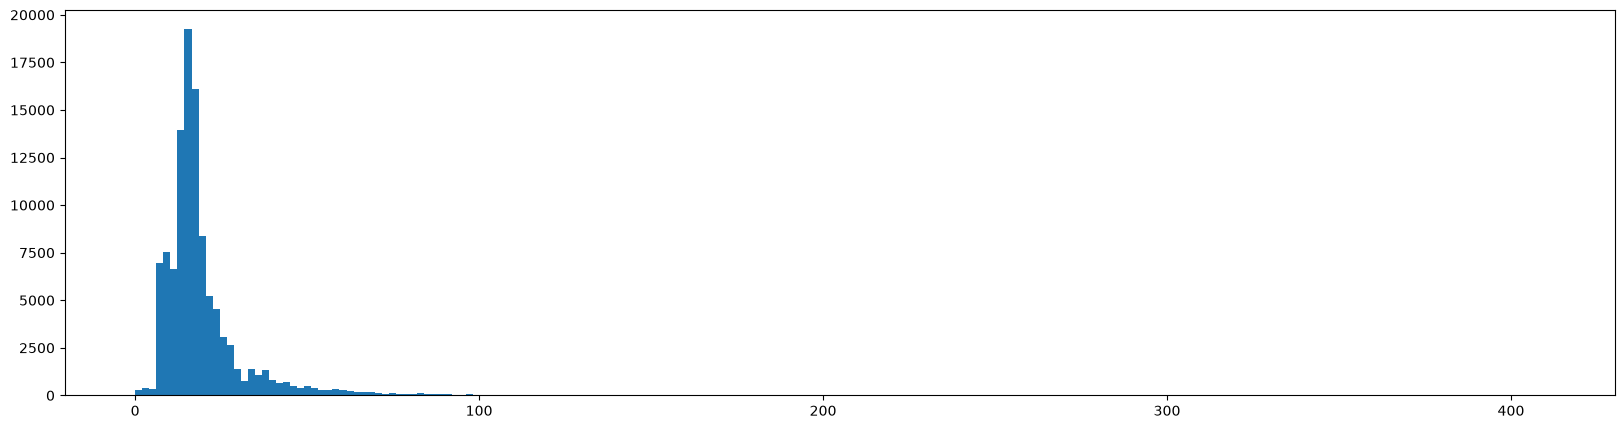

In [33]:
plt.figure(figsize=(20,5))
plt.hist(df["freight_value"], bins= 200)
plt.show()

Outliers: 11349
Tỷ lệ: 10.42 %


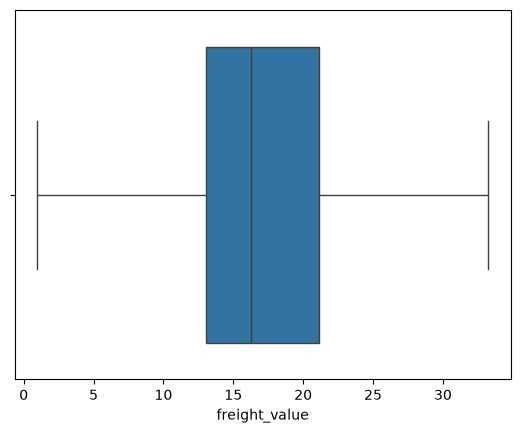

In [34]:
q1 = freight_value_2_1.loc[4, "freight_value"]
q3 = freight_value_2_1.loc[6, "freight_value"]
lower = q1 - 1.5 * (q3 - q1)
upper = q3 + 1.5 * (q3 - q1)

outliers = (
    (df["freight_value"] < lower) |
    (df["freight_value"] > upper)
)

print("Outliers:", outliers.sum())
print("Tỷ lệ:", round(outliers.mean() * 100, 2), "%")

sns.boxplot(data=df, x="freight_value", showfliers=False)
plt.show()


**Phát hiện:** Mean **20,01** > Median **16,28 BRL**; 50% item nằm trong **13,08–21,15 BRL**, Max **409,68 BRL** → phân phối lệch phải. Theo IQR (**0,975–33,255 BRL**) có **11.349 item (10,42%)** ngoài ngưỡng.

**SQL:** Query 1 xác nhận thống kê; Query 8 cho thấy nhiều trường hợp phí rất cao đi kèm hàng nặng/xa, **chưa chứng minh từng khoản phí là đúng**.

**Quyết định:** Không xóa outlier chỉ vì IQR; dùng **MAE**, theo dõi thêm **RMSE** và sai số nhóm phí cao.

### 2.2. Phí vận chuyển theo thời gian

**Mục đích:** Xem số item, Mean và Median thay đổi theo tháng để thử tính hữu ích của thời gian trong dự đoán.

**Phương pháp:** Biểu đồ cột (số item), đường (Mean/Median), bảng so sánh tháng có Mean thấp nhất và cao nhất.

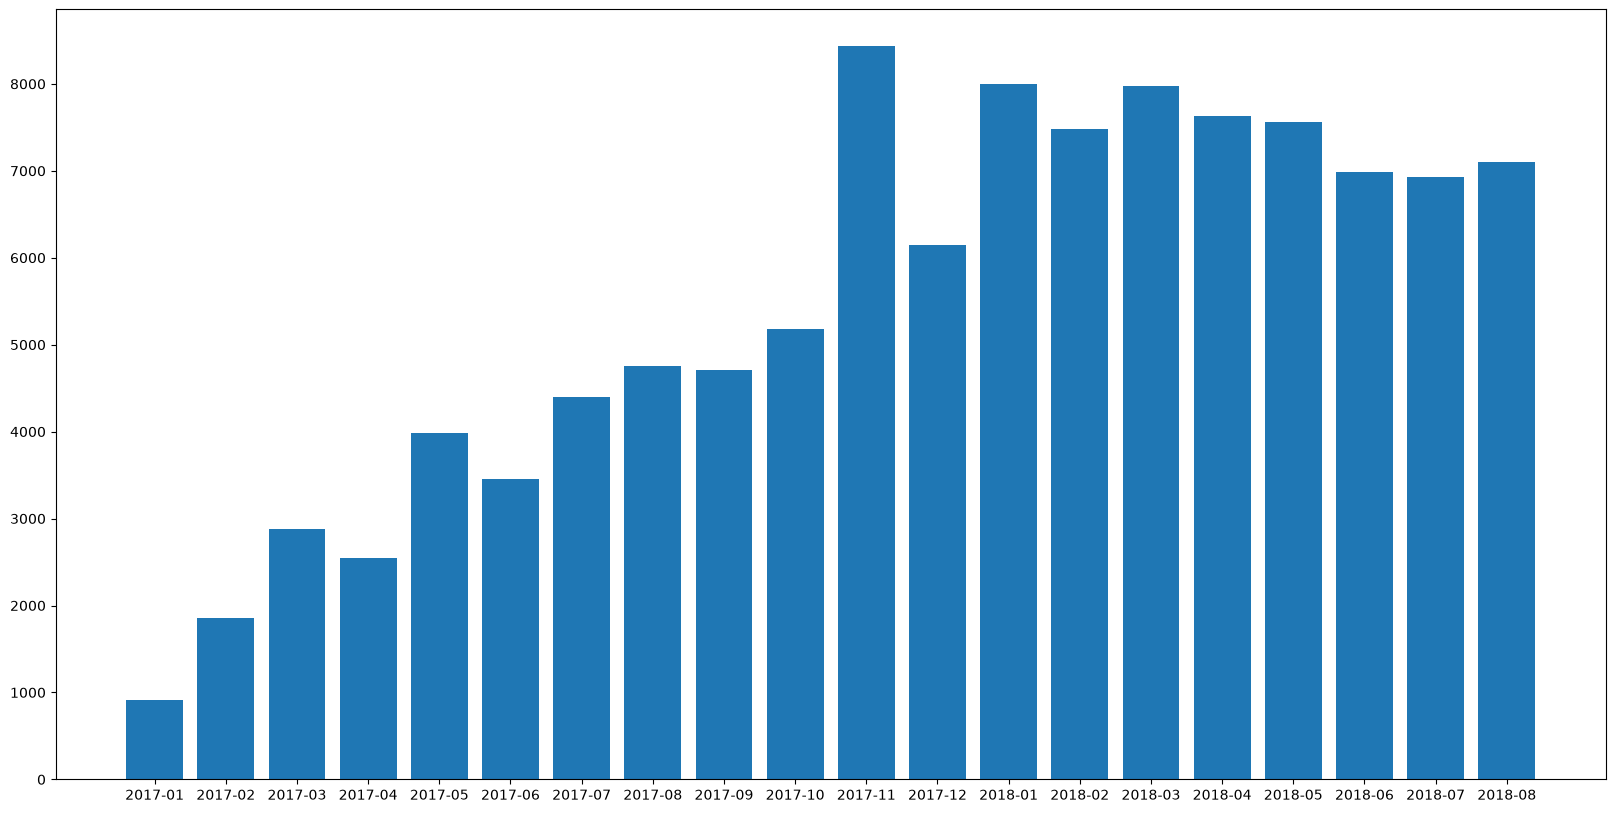

In [35]:
df["month"] = df["order_purchase_timestamp"].dt.strftime("%Y-%m")

df2_2 = df.groupby("month")["freight_value"].count().reset_index()
df2_2 = df2_2.sort_values(by="month", ascending=True)
plt.figure(figsize=(20, 10))
plt.bar(df2_2["month"], df2_2["freight_value"])
plt.show()

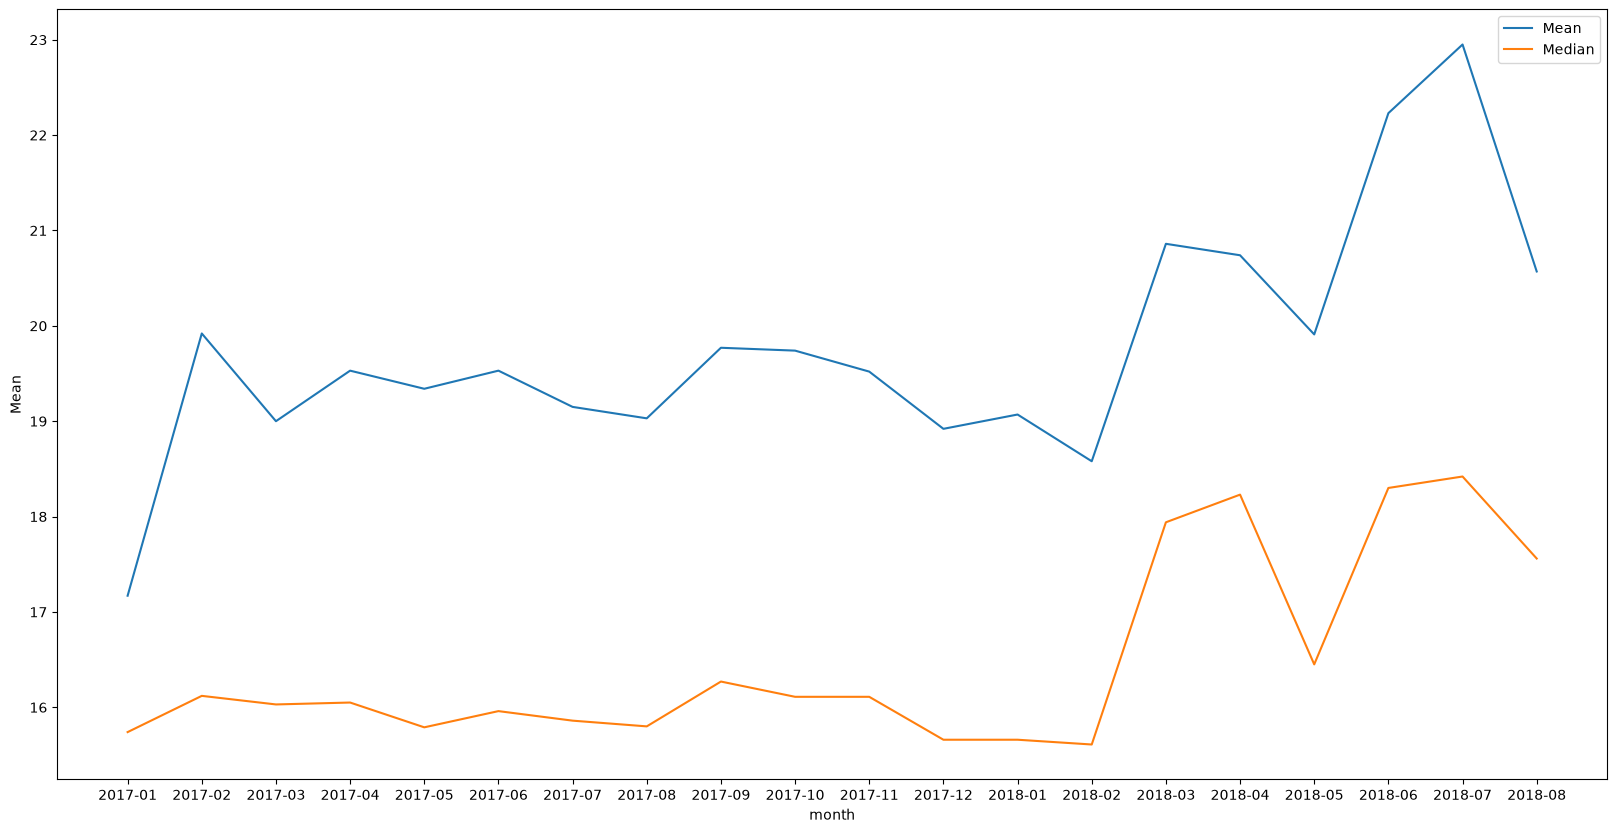

In [36]:
df2_2 = df.groupby("month").agg(Mean = ("freight_value","mean"), Median=("freight_value","median")).round(2).reset_index()
plt.figure(figsize=(20,10))
sns.lineplot(data=df2_2, x="month", y="Mean", label="Mean")
sns.lineplot(data=df2_2, x="month", y="Median", label="Median")
plt.show()

### Nhận xét biến động theo tháng

- **2017:** Số lượng order items tăng, phù hợp với xu hướng phát triển thương mại điện tử Brazil.
- **11/2017:** Đạt đỉnh, có thể liên quan đến Black Friday (Olist ghi nhận doanh số tăng 360% so với thứ Sáu thông thường).
- **12/2017:** Số lượng giảm sau Black Friday.
- **05–06/2018:** Sụt giảm có thể liên quan đến cuộc đình công vận tải tại Brazil (21/05/2018), gây gián đoạn logistics.
- **07–08/2018:** Số lượng tương đối ổn định.

In [37]:

d = df[df["month"].isin(["2017-01", "2018-07"])].copy()
d["high_freight"] = d["freight_value"] >= 40

result = d.groupby("month").agg(
    items=("freight_value", "count"),
    mean=("freight_value", "mean"),
    median=("freight_value", "median"),
    weight=("weight_g", "mean"),
    distance=("distance_km", "mean"),
    high_pct=("high_freight", "mean")
)

result["high_pct"] *= 100
display(result.round(2))


,items,mean,median,weight,distance,high_pct
month,,,,,,
2017-01,912,17.17,15.74,2054.11,619.41,3.29
2018-07,6934,22.95,18.42,1864.27,607.05,10.85


**Phát hiện:** Mean thấp nhất **01/2017: 17,17 BRL (912 item)**, cao nhất **07/2018: 22,95 BRL (6.934 item)**; Median **15,74 → 18,42 BRL**. Tỷ lệ phí ≥40 BRL **3,29% → 10,85%**. Cân nặng và khoảng cách TB không tăng tương ứng.

**SQL:** Query 7 xác nhận xu hướng tháng; Query 2–3 chỉ nêu liên hệ chung với cân nặng/khoảng cách, **không giải thích riêng chênh lệch hai tháng**. Tháng 01 có ít item nên cần thận trọng.

**Quyết định:** Giữ dữ liệu, thử biến thời gian, **chia train/validation/test theo thời gian**; chưa đủ bằng chứng kết luận mùa vụ.

## 3. Các yếu tố liên quan đến phí vận chuyển

**Mục đích:** Tìm các biến có sẵn lúc báo giá và đáng thử trong Modeling. Scatterplot cho xu hướng; Pearson đo liên hệ tuyến tính; SQL đối chiếu theo nhóm.

**Lưu ý:** SQL Query 4 (`same_state`) và Query 6 (`order_n_items`) dùng bản 27 cột, **không có trong CSV clean 10 cột**.

### 3.1. Cân nặng (`weight_g`)

**Câu hỏi:** Cân nặng có liên hệ với phí không? **Kiểm tra:** Scatterplot, Pearson, SQL Query 2.

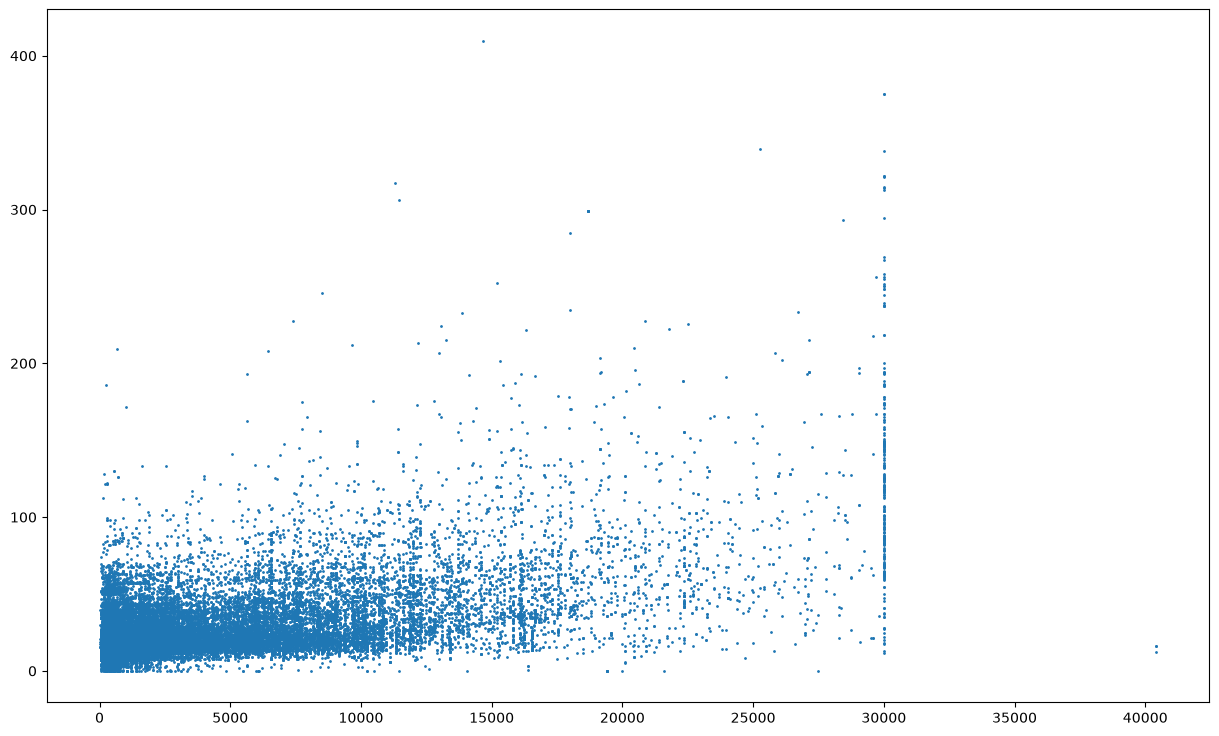

In [38]:
df3_1 = df[["weight_g","freight_value"]]
plt.figure(figsize=(15,9))
plt.scatter(df3_1["weight_g"], df3_1["freight_value"], s=1)
plt.show()

In [39]:
cor = df3_1[["weight_g","freight_value"]].corr(method="pearson")
display(cor.round(2))

,weight_g,freight_value
weight_g,1.00,0.61
freight_value,0.61,1.00


**Phát hiện:** Pearson **r ≈ 0,61**; cùng cân nặng vẫn có nhiều mức phí. **SQL Query 2:** Dưới 500g **15,17 BRL**, từ 5kg **39,62 BRL**.

**Bất thường:** Vệt thẳng ở **30.000g** gồm 259 item; kiểm tra tại mục 4.1. SQL Query 8 cũng ghi nhận nhóm hàng nặng trong các phí cao nhất.

**Quyết định:** Thử `weight_g`; không tự sửa/xóa các item 30kg.

### 3.2. Thể tích (`volume_cm3`)

**Câu hỏi:** Hàng cồng kềnh có thường có phí cao không? **Kiểm tra:** Scatterplot và Pearson; SQL hiện tại chưa có query riêng cho thể tích.

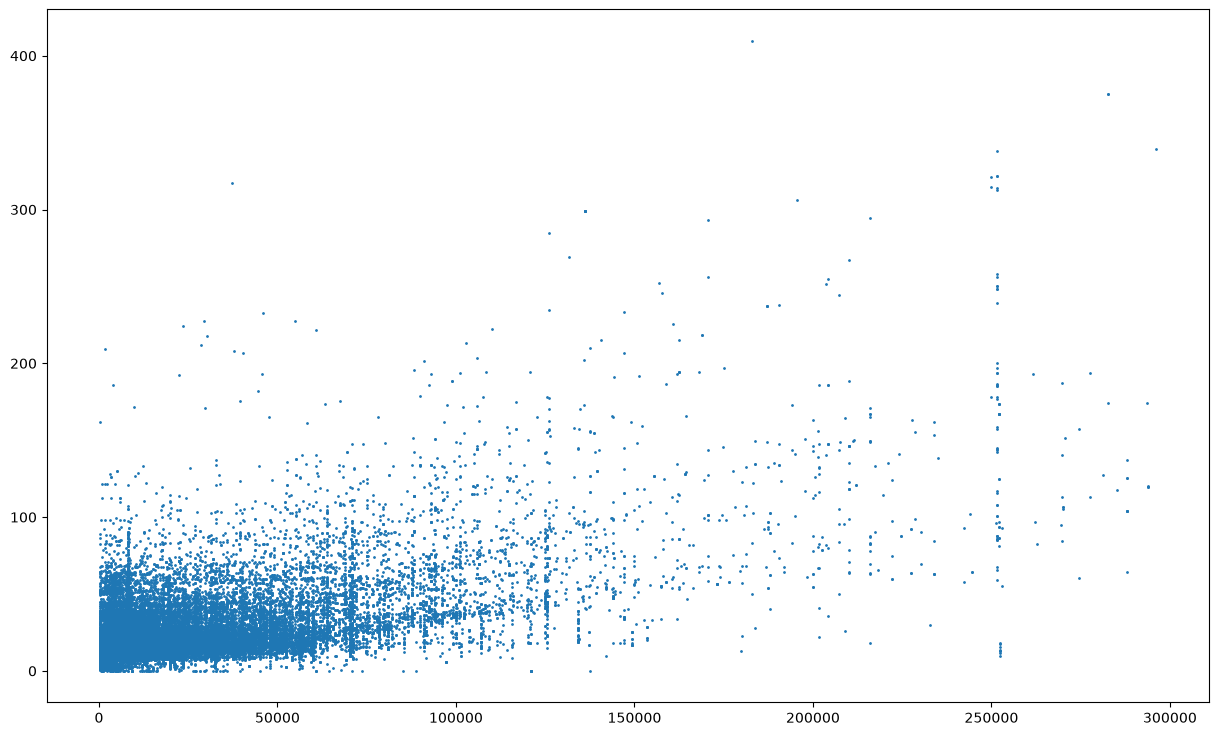

In [40]:
df3_2 = df[["volume_cm3","freight_value"]]
plt.figure(figsize=(15,9))
plt.scatter(df3_2["volume_cm3"], df3_2["freight_value"], s=1)
plt.show()

In [41]:
cor = df3_2[["volume_cm3","freight_value"]].corr(method="pearson")
display(cor.round(2))

,volume_cm3,freight_value
volume_cm3,1.00,0.58
freight_value,0.58,1.00


**Phát hiện:** Thể tích và phí có **r ≈ 0,58**, điểm phân tán rộng; thể tích tối đa **296.208 cm³**. Cân nặng và thể tích tương quan **r ≈ 0,81**.

**Quyết định:** Thử `volume_cm3` cùng cân nặng, kiểm tra đóng góp bằng validation; tương quan cao không có nghĩa phải xóa một biến.

### 3.3. Khoảng cách (`distance_km`)

**Câu hỏi:** Vận chuyển xa có thường có phí cao hơn không? **Kiểm tra:** Scatterplot, Pearson, SQL Query 3. Khoảng cách từ ZIP là **đường chim bay**, không phải tuyến xe thực.

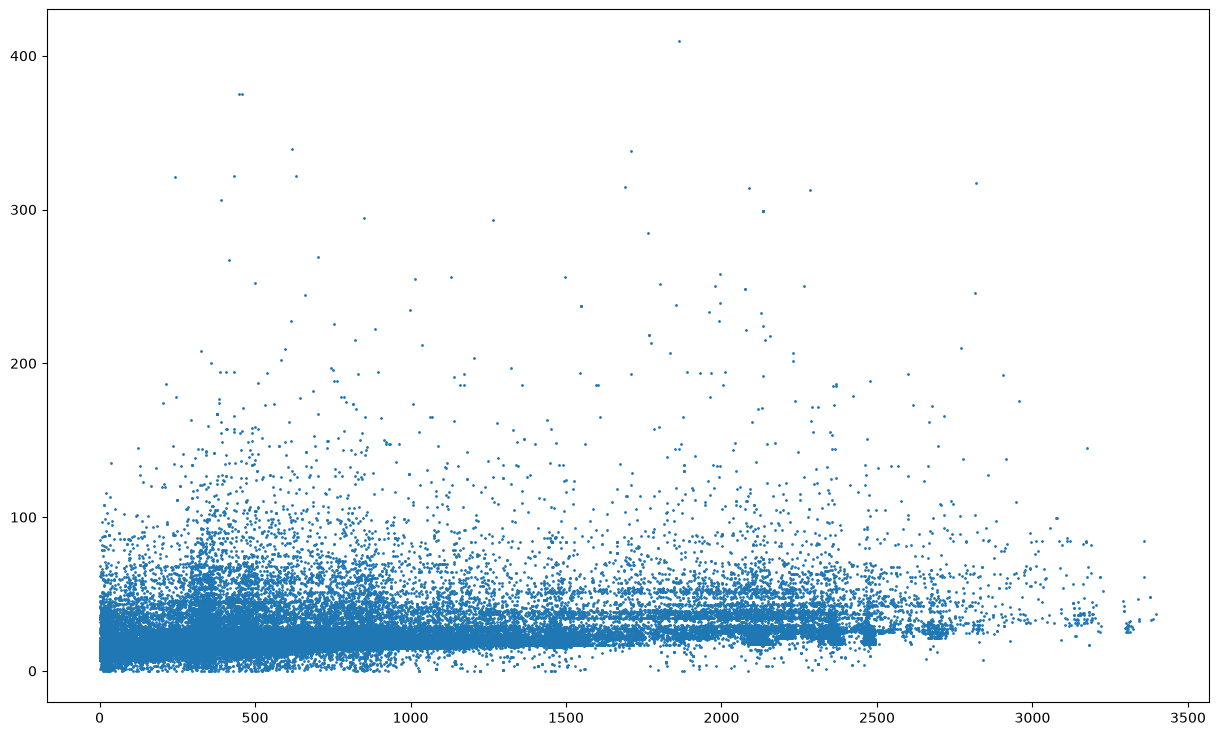

In [42]:
df3_3 = df[["distance_km","freight_value"]]
plt.figure(figsize=(15,9))
plt.scatter(df3_3["distance_km"], df3_3["freight_value"], s=1)
plt.show()

In [43]:
cor = df3_3[["distance_km","freight_value"]].corr(method="pearson")
display(cor.round(2))

,distance_km,freight_value
distance_km,1.00,0.39
freight_value,0.39,1.00


**Phát hiện:** Pearson **r ≈ 0,39**, độ phân tán lớn. **SQL Query 3:** Dưới 200km **12,66 BRL**, từ 1.500km **35,91 BRL**.

**Giải thích:** Khoảng cách liên quan đến phí, nhưng không đủ giải thích mọi item vì còn khác biệt về hàng hóa và dịch vụ vận chuyển.

**Quyết định:** Thử `distance_km`; nêu rõ đây là khoảng cách ước tính.

### 3.4. Giá sản phẩm (`price`)

**Câu hỏi:** Hàng đắt có luôn tốn phí cao hơn không? **Kiểm tra:** Scatterplot và Pearson (SQL chưa có query riêng về giá).

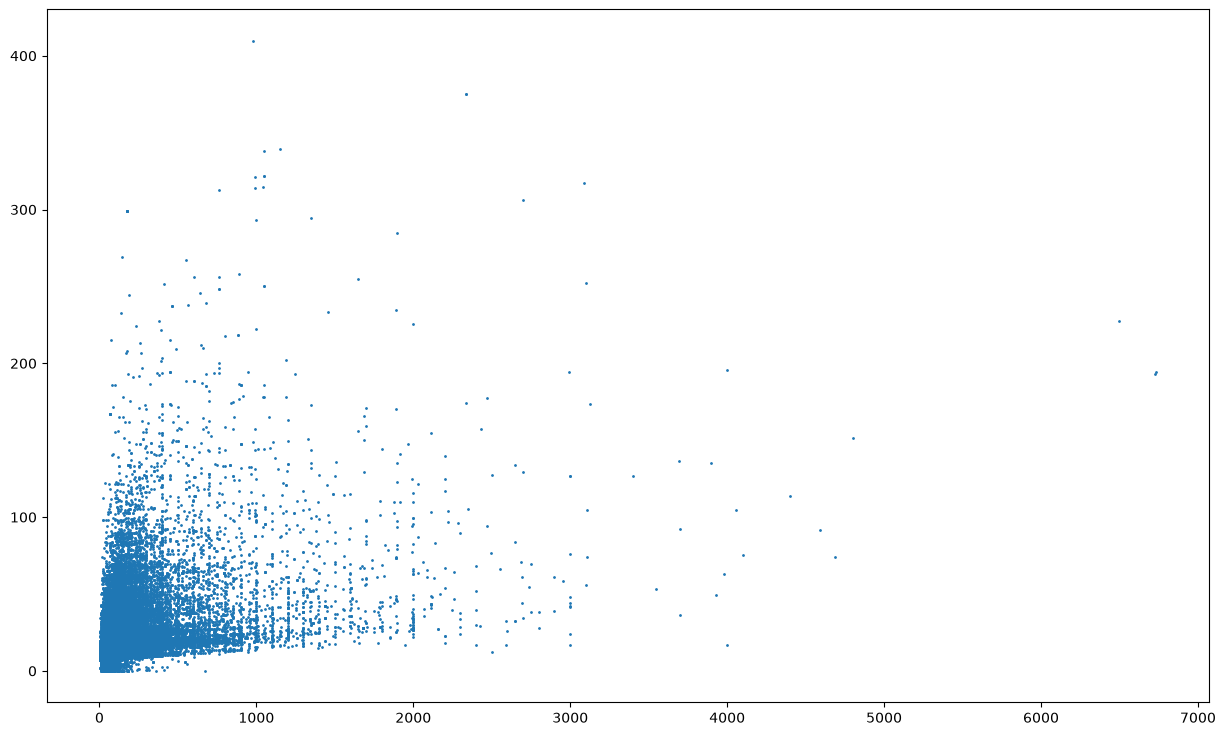

In [44]:
df3_4 = df[["price","freight_value"]]
plt.figure(figsize=(15,9))
plt.scatter(df3_4["price"], df3_4["freight_value"], s=1)
plt.show()

In [45]:
cor = df3_4[["price","freight_value"]].corr(method="pearson")
display(cor.round(2))

,price,freight_value
price,1.00,0.41
freight_value,0.41,1.00


**Phát hiện:** Tương quan với phí **r ≈ 0,41** nhưng các điểm phân tán rộng; giá cao không bảo đảm phí cao.

**Quyết định:** Thử `price` và đánh giá bằng MAE trên validation.

### 3.5. Danh mục (`category`)

**Câu hỏi:** Phí có khác giữa các danh mục không? **EDA:** 20 danh mục phổ biến nhất và boxplot. **SQL Query 5:** Top danh mục theo Mean với ít nhất 300 item; **hai cách chọn nhóm khác nhau**.

In [46]:
category_group = df.groupby("category")["freight_value"]
df3_8 = category_group.agg(Count="count", Mean="mean")
df3_8["Q1"] = category_group.quantile(0.25)
df3_8["Q2"] = category_group.quantile(0.5)
df3_8["Q3"] = category_group.quantile(0.75)
df3_8 = df3_8.sort_values(by="Count", ascending=False).head(20).reset_index()
display(df3_8.round(2))


,category,Count,Mean,Q1,Q2,Q3
0,bed_bath_table,10901,18.43,13.29,16.19,19.72
1,health_beauty,9394,18.92,11.98,15.79,19.80
2,sports_leisure,8398,19.36,13.39,16.25,20.72
3,furniture_decor,7979,20.89,13.08,16.43,22.20
4,computers_accessories,7611,18.83,13.11,15.98,20.29
5,housewares,6765,21.02,13.01,16.76,22.66
6,watches_gifts,5621,17.37,13.05,16.01,19.22
7,telephony,4394,15.64,11.02,15.10,18.23
8,garden_tools,4196,22.94,13.78,17.67,26.25
9,auto,4121,21.86,13.74,17.60,23.49


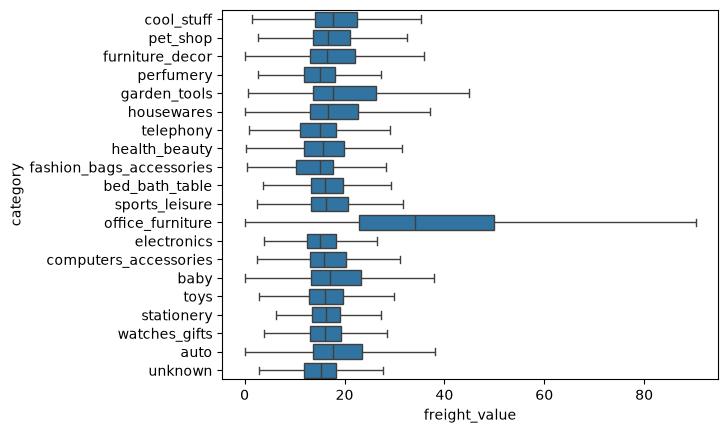

In [47]:
df3_8_boxplot = df[df["category"].isin(df3_8["category"])]
sns.boxplot(data=df3_8_boxplot, x="freight_value", y="category",showfliers=False)
plt.show()

**Phát hiện:** Các danh mục có Mean/Median và IQR khác nhau, nhưng phân phối vẫn chồng lấn. **SQL Query 5:** `office_furniture` **40,17 BRL**, nặng TB **11,33kg**; `furniture_living_room` **37,43 BRL**, nặng TB **8,73kg**.

**Giải thích:** Phí khác biệt có thể đi cùng khác biệt về cân nặng/thể tích; chưa chứng minh tác động riêng của category.

**Quyết định:** Thử `category` bằng one-hot, kiểm tra trên validation.

### 3.6. Tương quan tổng hợp

**Mục đích:** So sánh các biến số và phát hiện thông tin chồng lặp. Heatmap không khẳng định biến nào quan trọng nhất cho dự đoán.

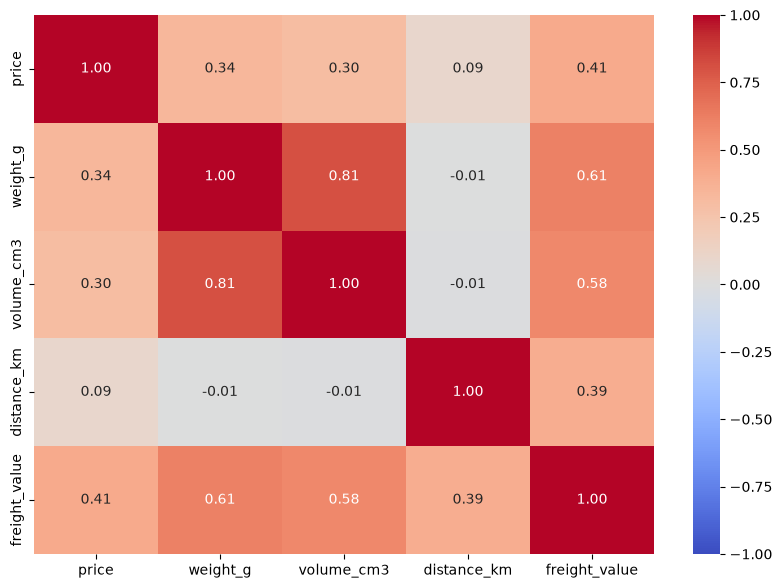

In [48]:
cols = ['price', 'weight_g', 'volume_cm3', 'distance_km','freight_value']
corr = df[cols].corr(method='pearson')

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()


**Bằng chứng:** Với phí, Pearson của cân nặng **0,61**, thể tích **0,58**, giá **0,41**, khoảng cách **0,39**. Cân nặng và thể tích có **r ≈ 0,81**.

**SQL Query 2, 3, 5** củng cố xu hướng theo nhóm, không chứng minh nhân quả.

**Quyết định:** Thử 4 biến số và `category`; không mặc định đưa các mã ID vào mô hình.

### 3.7. Kết luận

### Nhận xét tổng hợp Scatterplot

- **Weight (r = 0.61):** Phí có xu hướng tăng theo cân nặng; xuất hiện cụm bất thường tại 30kg.
- **Volume (r = 0.58):** Hàng cồng kềnh thường có phí cao hơn, nhưng các điểm vẫn phân tán.
- **Distance (r = 0.39):** Khoảng cách càng xa, phí có xu hướng tăng nhưng biến động lớn.
- **Price (r = 0.41):** Các điểm phân tán rộng; sản phẩm đắt chưa chắc có phí cao.

**Kết luận:** Phần lớn quan sát tập trung ở vùng giá trị X thấp. Cả 4 biến có tương quan dương với phí nhưng không biến nào giải thích hoàn toàn sự biến động.

### Nhận xét Heatmap

- **Cân nặng (r = 0.61):** Tương quan dương mạnh nhất với phí vận chuyển.
- **Thể tích (r = 0.58):** Tương quan dương tương đối mạnh với phí.
- **Giá (r = 0.41):** Tương quan dương mức trung bình.
- **Khoảng cách (r = 0.39):** Tương quan dương nhưng yếu hơn các biến còn lại.
- **Cân nặng và thể tích (r = 0.81):** Tương quan cao, có nguy cơ đa cộng tuyến trong Linear Regression.
- **Khoảng cách với cân nặng và thể tích (r ≈ -0.01):** Hầu như không có tương quan tuyến tính.

**Kết luận:** Cả 4 biến đều có tương quan dương với phí vận chuyển nhưng không biến nào giải thích hoàn toàn sự biến thiên.


**Quyết định Modeling:** Dùng Linear Regression làm baseline, thử Random Forest cho quan hệ phi tuyến; chọn theo **MAE trên validation theo thời gian**, không chọn theo tương quan hay test.

## 4. Giải thích các cụm bất thường

**Mục tiêu:** Kiểm tra những cụm điểm lạ ở scatterplot phần 3: chúng có đặc điểm gì, có hợp lý không và có cần loại bỏ không? **Outlier thống kê không đồng nghĩa dữ liệu lỗi.**

### 4.1. Phân tích các cụm bất thường

**Mục tiêu:** Kiểm tra các cụm bất thường trên scatterplot để đánh giá tính hợp lý trước Modeling.

**Phương pháp:** Lọc theo cân nặng, thể tích, khoảng cách và phí vận chuyển; kiểm tra danh mục và đặc điểm sản phẩm.

**Phát hiện:**
- **30kg:** Xuất hiện ở nhiều danh mục, đặc biệt `health_beauty` (59 item). Việc tập trung đúng 30kg cần được xác minh.
- **40,425kg:** 3 item cùng seller, thể tích 23.660 cm³ nhưng phí chỉ 12–16 BRL → đáng nghi.
- **Thể tích lớn:** Tập trung ở `health_beauty` và nhóm nội thất; có thể là hàng cồng kềnh.
- **Khoảng cách >2.500km:** Có cả hàng nhẹ nhưng phí cao → khoảng cách có thể góp phần giải thích.
- **Phí >200 BRL:** Nhiều item nặng 18–30kg hoặc có thể tích lớn, phù hợp với đặc điểm hàng khó vận chuyển.

In [49]:

# 0. Kiểm tra 1 outlier phí ship có thể hợp lệ
display(df[df["freight_value"] > upper][
    ["category", "weight_g", "volume_cm3", "distance_km", "freight_value"]
].head(3))

# 1. Cụm 30kg thuộc danh mục nào?
display(df[df["weight_g"] == 30000]["category"].value_counts().head(5))

# 2. Cụm trên 40kg có đặc điểm gì?
display(df[df["weight_g"] > 40000][["category", "volume_cm3", "freight_value"]])

# 3. Cụm thể tích lớn thuộc danh mục nào?
display(df[df["volume_cm3"] >= 250000]["category"].value_counts().head(5))

# 4. Cụm giao xa có đặc điểm gì?
display(df[df["distance_km"] > 2500][["category", "weight_g", "freight_value"]].head(5))

# 5. Cụm phí rất cao có đặc điểm gì?
display(df[df["freight_value"] > 200][["category", "weight_g", "volume_cm3", "distance_km"]].head(5))


,category,weight_g,volume_cm3,distance_km,freight_value
7,garden_tools,13805.0,118125.0,548.089416,70.75
22,office_furniture,9375.0,56430.0,257.242800,44.40
39,computers_accessories,3407.0,14168.0,1445.115851,44.29


category
health_beauty            59
housewares               42
sports_leisure           27
furniture_decor          20
furniture_living_room    19
Name: count, dtype: int64

,category,volume_cm3,freight_value
31676,bed_bath_table,23660.0,16.32
47141,bed_bath_table,23660.0,12.06
61844,bed_bath_table,23660.0,16.32


category
health_beauty            47
furniture_living_room    14
furniture_decor          13
housewares               10
bed_bath_table            8
Name: count, dtype: int64

,category,weight_g,freight_value
153,watches_gifts,700.0,54.02
236,garden_tools,625.0,34.15
305,auto,1900.0,67.69
372,toys,250.0,21.18
641,fashion_bags_accessories,100.0,25.65


,category,weight_g,volume_cm3,distance_km
1086,musical_instruments,30000.0,216000.0,851.264184
3185,housewares,30000.0,282750.0,456.737056
3462,construction_tools_construction,30000.0,250000.0,241.528575
4717,musical_instruments,18000.0,126000.0,997.162889
4872,health_beauty,30000.0,251625.0,632.380720



### Kết luận và quyết định

- **Phí >33,255 BRL:** Các mẫu outlier có cân nặng lớn, thể tích lớn hoặc giao xa → có cơ sở hợp lý, nhưng chưa đủ thông tin xác nhận hoàn toàn.
- **40,425kg:** 3 item cùng danh mục `bed_bath_table`, thể tích 23.660 cm³ nhưng phí chỉ 12–16 BRL → đáng kiểm tra.
- **Thể tích lớn:** Xuất hiện ở `health_beauty` (47 item) và nhóm nội thất → có thể liên quan đến hàng cồng kềnh.
- **Giao xa:** Có item chỉ 700g nhưng phí 54,02 BRL → khoảng cách có thể góp phần làm phí cao.
- **Phí >200 BRL:** Các ví dụ có cân nặng 18–30kg, thể tích 126.000–282.750 cm³ → phù hợp với đặc điểm hàng nặng, cồng kềnh.

**Kết luận:** Nhiều điểm bất thường có đặc điểm phù hợp với vận chuyển thực tế, nhưng chưa đủ bằng chứng xác nhận tất cả đều hợp lệ.

**Quyết định:** Không tự động xóa outlier, giữ cho Modeling.

### 4.2. Hạn chế của dữ liệu

- **Có `seller_id`**, nhưng CSV **không có mã số thuế người bán**, địa chỉ người bán/người mua hoặc thông tin chi tiết để giải thích từng bên.
- **Thiếu** hãng vận chuyển, loại dịch vụ, tuyến đường thực chạy, giá cước và chính sách giảm phí → **không thể xác định nguyên nhân chính xác** của từng phí cao/thấp.
- `distance_km` là **đường chim bay theo ZIP**; 26 item có khoảng cách 0km không có nghĩa giao hàng miễn phí.
- Dữ liệu chỉ gồm **đơn đã giao, 01/2017–08/2018, phí >0**; kết luận chỉ áp dụng cho phạm vi này.

**Hướng xử lý:** Không suy đoán nguyên nhân/điền giá trị giả; bổ sung dữ liệu nguồn nếu có, hoặc nêu rõ giới hạn trong báo cáo.

## 5. Đề xuất mô hình dự đoán phí vận chuyển

### 5.1. Mục tiêu

Dự đoán `freight_value` (BRL/item) dựa trên các đặc trưng có sẵn khi đặt hàng.

### 5.2. Lựa chọn đặc trưng từ EDA và SQL

| Biến | Pearson (Heatmap) | Bằng chứng SQL |
|---|---:|---|
| `weight_g` | 0,613 | Query 5: Phí TB tăng từ 15,17 lên 39,62 BRL giữa nhóm dưới 500g và trên 5kg |
| `volume_cm3` | 0,584 | Query 6: Phí TB tăng từ 14,91 lên 27,36 BRL giữa nhóm thể tích nhỏ nhất và lớn nhất |
| `distance_km` | 0,395 | Query 7: Phí TB tăng từ 12,66 lên 35,91 BRL giữa nhóm dưới 200km và trên 1.500km |
| `price` | 0,414 | Query 8: Phí TB tăng từ 14,73 lên 34,16 BRL giữa nhóm giá dưới 50 và trên 200 BRL |

**Nhận xét:** Cả 4 biến đều có tương quan dương với phí vận chuyển. SQL xác nhận phí trung bình có xu hướng tăng theo từng nhóm đặc trưng, phù hợp với kết quả Heatmap.

**Quyết định:** Chọn `weight_g`, `volume_cm3`, `distance_km`, `price` làm 4 biến đầu vào.

### 5.3. Các biến không lựa chọn

- **`category`:** Phần lớn boxplot chồng lấn; SQL Query 1 cho thấy phí cao ở một số danh mục đi kèm cân nặng lớn. Nhóm ưu tiên các đặc trưng vật lý trực tiếp.
- **Tháng đặt hàng:** Phí biến động nhưng chưa chứng minh được quy luật mùa vụ ổn định.
- **`seller_id`, `order_id`, `order_item_id`:** Là các mã định danh, không được sử dụng trong mô hình ban đầu.

Việc loại các biến khỏi mô hình hiện tại nhằm đơn giản hóa, không khẳng định chúng hoàn toàn không có giá trị dự đoán.

### 5.4. Đề xuất mô hình

**Linear Regression:**
- Là mô hình nền, đơn giản và dễ giải thích.
- Kiểm tra khả năng dự đoán bằng quan hệ tuyến tính.

**Random Forest Regressor:**
- Học được quan hệ phi tuyến và tương tác giữa các biến.
- Phù hợp để thử nghiệm vì scatterplot cho thấy phí phân tán rộng, không tuân theo quan hệ tuyến tính đơn giản.

**Đề xuất:** So sánh hai mô hình trên cùng 4 đặc trưng; ưu tiên mô hình có sai số thấp hơn.

### 5.5. Đánh giá mô hình

- **Train/Test:** Chia ngẫu nhiên 80/20, `random_state=42`.
- **MAE:** Chỉ số chính, đo sai số trung bình bằng BRL.
- **RMSE:** Nhấn mạnh các trường hợp dự đoán sai lớn.
- **R²:** Đánh giá mức độ giải thích biến thiên của phí.

**Giới hạn:** Chia ngẫu nhiên chưa chứng minh khả năng dự đoán các tháng tương lai; cần kiểm chứng thêm bằng cách chia theo thời gian và tránh để item cùng đơn hàng xuất hiện ở cả Train và Test.

### Kết luận

**Heatmap và SQL cung cấp bằng chứng nhất quán để lựa chọn 4 đặc trưng số.** Nhóm sử dụng Linear Regression làm mô hình nền và Random Forest để kiểm tra khả năng cải thiện dự đoán. Hiệu quả thực tế được đánh giá ở Phần 6 — Modeling.

**Nguồn tham khảo:**
1. [Olist – Black Friday 2017](https://www.gov.br/mdic/pt-br/images/REPOSITORIO/scs/decos/Informativo_2017/233a_Informativoa_daa_Secretariaa_dea_Servia_oa_2017.pdf)
2. [Reuters – Đình công vận tải Brazil 2018](https://economia.uol.com.br/noticias/reuters/2018/06/04/comercio-eletronico-no-brasil-deixa-de-faturar-r4072-mi-com-greve-de-caminhoneiros.amp.htm)
3. [FecomercioSP – Thương mại điện tử Brazil 2017](https://www.fecomercio.com.br/noticia/comercio-eletronico-fatura-r-47-bilhoes-em-2017-impulsionado-por-aumento-de-pedidos-1)